<a href="https://colab.research.google.com/github/Memo1714/PRACTICA_PERCEPTRON_MELO/blob/main/PRACTICA_PERCEPTRON_MELO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Literal 1.1 – Carga del Dataset


La guía proporciona 23 puntos con dos variables de entrada (x1, x2) y una clase (-1 o 1).

In [48]:
# Dataset de la práctica

X = [
    [1, 7], [1, 3], [3, 4], [4, 6],
    [4, 2], [6, 6], [6, 2], [6, 0],
    [7, 4], [9, 3], [9, 1], [11, 1],
    [12, 3], [16, 2],
    [4, 8], [6, 8], [8, 9], [9, 7],
    [10, 11], [12, 9], [12, 6],
    [14, 7], [16, 4]
]

y = [
    -1, -1, -1, -1, -1, -1, -1,
    -1, -1, -1, -1, -1, -1, -1,
     1,  1,  1,  1,  1,  1,  1,
     1,  1
]

print("Dataset cargado correctamente")
print("Total de instancias:", len(X))

Dataset cargado correctamente
Total de instancias: 23


Explicación: X contiene las coordenadas de los puntos y y contiene la clase a la que pertenece cada uno. Ambas listas tienen el mismo número de elementos.

# Literal 1.a – Inspección inicial
Debemos identificar el número de instancias, las variables de entrada, el número de clases y la cantidad de puntos por clase. Sin usar librerías de análisis de datos.

In [49]:
total = len(X)
clase_negativa = 0
clase_positiva = 0

for clase in y:
    if clase == -1:
        clase_negativa += 1
    else:
        clase_positiva += 1

print("Total de instancias:", total)
print("Variables de entrada: x1 y x2")
print("Número de clases: 2")
print("Puntos clase -1:", clase_negativa)
print("Puntos clase +1:", clase_positiva)

Total de instancias: 23
Variables de entrada: x1 y x2
Número de clases: 2
Puntos clase -1: 14
Puntos clase +1: 9


#¿Qué representa cada fila de X? ¿Qué representa cada valor del vector y? ¿Por qué el problema se considera de clasificación binaria

Cada fila de X representa una instancia con dos características numéricas, x1 y x2. Cada valor del vector y indica la clase correspondiente a esa instancia. Se considera clasificación binaria porque únicamente existen dos clases posibles: -1 y +1.

# Literal 1.b – Separación visual de las clases
Crearemos una función para representar los puntos en un plano cartesiano, utilizando círculos azules para la clase -1 y cruces rojas para la clase +1.

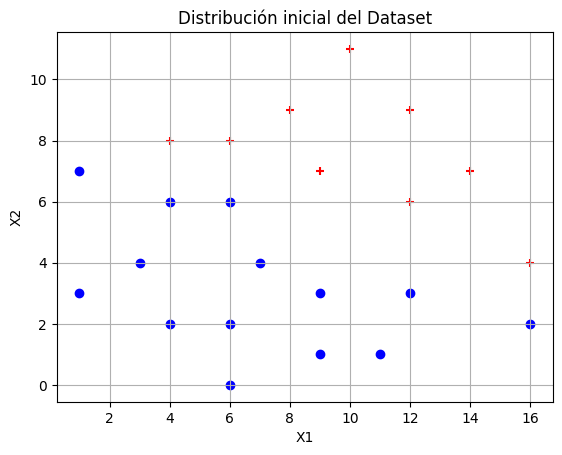

In [50]:
import matplotlib.pyplot as plt

def graficar_datos(X, y):
    for i in range(len(X)):
        if y[i] == -1:
            plt.scatter(X[i][0], X[i][1],
                        color="blue", marker="o")
        else:
            plt.scatter(X[i][0], X[i][1],
                        color="red", marker="+")

    plt.title("Distribución inicial del Dataset")
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.grid(True)
    plt.show()

graficar_datos(X, y)

# Observando únicamente la gráfica, ¿parece posible separar las dos clases mediante una sola recta? Justifica tu respuesta.

Sí, visualmente parece posible separar ambas clases mediante una recta inclinada. Los puntos de la clase +1 se encuentran generalmente en la parte superior del plano, mientras que los de la clase -1 se concentran en la parte inferior.

# Fase 2. Fundamento del Perceptrón
El perceptrón calcula una suma ponderada:


Donde w0 es el sesgo o bias, mientras que w1 y w2 son los pesos asociados a las variables de entrada.
Literal 2.a – Vector de pesos
La función initialize_weights() debe generar tres pesos aleatorios entre -0.5 y 0.5.

In [51]:
import random

def initialize_weights():
    w0 = random.uniform(-0.5, 0.5)
    w1 = random.uniform(-0.5, 0.5)
    w2 = random.uniform(-0.5, 0.5)

    return [w0, w1, w2]

pesos = initialize_weights()
print("Pesos iniciales:", pesos)

Pesos iniciales: [0.30187011881751313, -0.06842285773721879, 0.31746319045064764]


# Explicación: random.uniform() genera valores decimales aleatorios dentro del rango especificado. Los pesos iniciales serán diferentes en cada ejecución.

#¿Por qué el vector de pesos tiene tres valores si cada instancia de entrada solo tiene dos variables? ¿Qué función cumple el bias?


El vector contiene tres valores porque existen dos pesos para las variables de entrada y uno adicional para el bias. El bias permite desplazar la frontera de decisión sin obligarla a pasar por el origen del plano cartesiano.


# Literal 2.b – Función de activación
La función escalón bipolar devuelve +1 cuando z >= 0 y -1 cuando z < 0.

In [52]:
def activation(z):
    if z >= 0:
        return 1
    else:
        return -1

print("Activación de 5:", activation(5))
print("Activación de -3:", activation(-3))
print("Activación de 0:", activation(0))

Activación de 5: 1
Activación de -3: -1
Activación de 0: 1


#Por qué en esta práctica se utilizan las etiquetas -1 y 1 en lugar de 0 y 1? ¿Qué ventaja tiene esta representación?

Se utilizan -1 y +1 porque permiten representar las dos clases de forma bipolar. Esto facilita la aplicación de la regla de actualización, ya que el signo de la etiqueta indica la dirección de la corrección de los pesos.


# Literal 2.c – Cálculo de salida
Implementaremos perceptron_compute(x, w) para calcular la suma ponderada y devolver la clase predicha.

In [53]:
def perceptron_compute(x, w):
    z = w[0] + w[1] * x[0] + w[2] * x[1]
    return activation(z)

# Prueba con tres instancias del dataset
for i in range(3):
    prediccion = perceptron_compute(X[i], pesos)

    print("Instancia:", X[i])
    print("Clase real:", y[i])
    print("Clase predicha:", prediccion)
    print("----------------------")

Instancia: [1, 7]
Clase real: -1
Clase predicha: 1
----------------------
Instancia: [1, 3]
Clase real: -1
Clase predicha: 1
----------------------
Instancia: [3, 4]
Clase real: -1
Clase predicha: 1
----------------------


#Explicación: Se toman los dos valores de cada instancia, se multiplican por sus respectivos pesos y se suma el bias. La función de activación transforma el resultado en una clase.

# ¿Cuál es la diferencia entre la suma ponderada z y la salida final del perceptrón? ¿Por qué no basta con calcular solo z?

La suma ponderada z es un valor numérico que puede ser positivo, negativo o cero. La salida final convierte ese valor en una clase mediante la función de activación. No basta con calcular z porque necesitamos una etiqueta concreta para clasificar la instancia.

# Fase 3. Visualización de la Frontera de Decisión
Literal 3.a – Función de graficación


La frontera de decisión está definida por:

In [54]:
def perceptron_plot(X, y, w, title):
    plt.figure(figsize=(8, 5))

    # Graficar los puntos
    for i in range(len(X)):
        if y[i] == -1:
            plt.scatter(X[i][0], X[i][1],
                        color="blue", marker="o")
        else:
            plt.scatter(X[i][0], X[i][1],
                        color="red", marker="+")

    # Calcular la frontera de decisión
    x1_min = min(p[0] for p in X) - 1
    x1_max = max(p[0] for p in X) + 1

    if w[2] != 0:
        x1_linea = [x1_min, x1_max]
        x2_linea = []

        for x1 in x1_linea:
            x2 = -(w[0] + w[1] * x1) / w[2]
            x2_linea.append(x2)

        plt.plot(x1_linea, x2_linea,
                 color="green", label="Frontera")
    elif w[1] != 0:
        x1 = -w[0] / w[1]
        plt.axvline(x1, color="green",
                    label="Frontera")

    plt.title(title)
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.xlim(x1_min, x1_max)
    plt.ylim(-2, 13)
    plt.grid(True)
    plt.legend(["Frontera", "Clase -1", "Clase +1"])
    plt.show()

# Explicación: Esta función representa las dos clases y calcula la recta a partir de los pesos. La posición e inclinación de la recta dependen de los valores de w0, w1 y w2.

# Qué representa geométricamente la recta generada por el perceptrón? ¿Qué ocurre si los pesos iniciales son aleatorios?

La recta representa la frontera que divide el plano en dos regiones de clasificación. Cuando los pesos son aleatorios, la recta también tiene una posición e inclinación iniciales aleatorias y no necesariamente separa correctamente las clases.

# Literal 3.b – Gráfica con pesos iniciales

Pesos iniciales: [0.22345967619556395, -0.28118890049342227, -0.338367816792694]


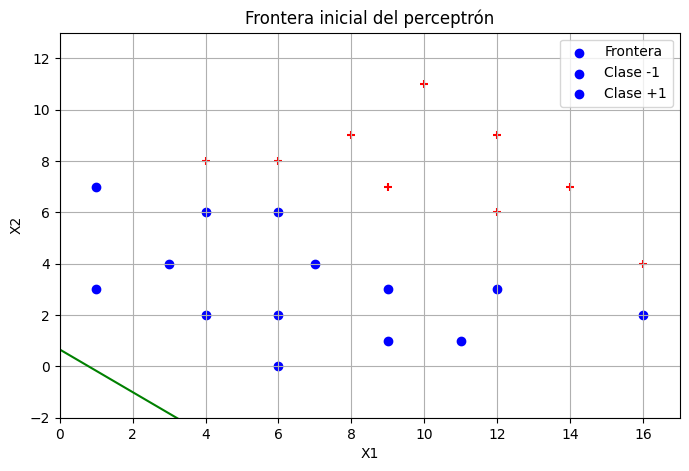

In [55]:
w_initial = initialize_weights()

print("Pesos iniciales:", w_initial)

perceptron_plot(
    X, y, w_initial,
    "Frontera inicial del perceptrón"
)

# ¿La frontera inicial clasifica correctamente los puntos? ¿Por qué no deberíamos esperar que una frontera con pesos aleatorios sea correcta?

La frontera inicial no necesariamente clasifica todos los puntos correctamente, porque los pesos fueron generados de manera aleatoria y todavía no han sido ajustados mediante el entrenamiento. Para determinar cuántos puntos clasifica correctamente, debemos comparar las predicciones con las etiquetas reales.

# Fase 4. Entrenamiento del Perceptrón
En esta fase implementaremos el aprendizaje manua

# Literal 4.a – Implementación de la función de aprendizaje
La función recibirá los datos, las etiquetas, los pesos iniciales, la tasa de aprendizaje y el número máximo de épocas.

In [56]:
def perceptron_learning(X, y, w, lr, max_epochs):

    w = w.copy()

    W_values = [w.copy()]
    E_values = []
    updates = 0
    epochs = 0

    for epoca in range(max_epochs):
        errores = 0

        for i in range(len(X)):
            prediccion = perceptron_compute(X[i], w)

            if prediccion != y[i]:
                errores += 1

                diferencia = y[i] - prediccion

                # Actualizar bias
                w[0] = w[0] + lr * diferencia

                # Actualizar pesos
                w[1] = w[1] + lr * diferencia * X[i][0]
                w[2] = w[2] + lr * diferencia * X[i][1]

                updates += 1

        # Guardar error de la época
        error = errores / len(X)
        E_values.append(error)

        # Guardar copia de los pesos
        W_values.append(w.copy())

        epochs += 1

        # Detener si no existen errores
        if errores == 0:
            break

    return w, epochs, updates, W_values, E_values

# Explicación:
- El ciclo externo recorre las épocas de entrenamiento.
- El ciclo interno evalúa cada instancia.
- Cuando una predicción es incorrecta, se modifican los pesos.
- Se registra el número de errores y se guarda una copia de los pesos.
- El entrenamiento termina cuando se completa una época sin errores o se alcanza el límite.[texto del enlace](https://)

# ¿Por qué es necesario incluir un número máximo de épocas? ¿Qué podría ocurrir si el dataset no fuera linealmente separable?

El número máximo de épocas evita que el entrenamiento continúe indefinidamente. Si el dataset no fuera linealmente separable, el perceptrón podría seguir actualizando sus pesos sin conseguir clasificar correctamente todos los puntos.

# Literal 4.b – Registro del error

In [57]:

errores = 0
E_values = []
error = errores / len(X)
E_values.append(error)
print("Error calculado:", error)

Error calculado: 0.0


Para comprobarlo, podemos realizar un entrenamiento de prueba.

In [58]:
w_prueba = initialize_weights()

resultado = perceptron_learning(
    X, y, w_prueba,
    lr=0.5,
    max_epochs=1000
)

print("Errores de las primeras épocas:")
print(resultado[4][:10])

Errores de las primeras épocas:
[0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043]


# ¿Qué significa que la tasa de error llegue a cero?

Significa que durante esa época el perceptrón clasificó correctamente todas las instancias del dataset, sin cometer errores.

#Literal 4.c – Registro de pesos

Podemos verificar los valores registrados.

In [59]:
pesos_registrados = resultado[3]

print("Pesos iniciales:", pesos_registrados[0])
print("Pesos finales:", pesos_registrados[-1])
print("Estados registrados:", len(pesos_registrados))

Pesos iniciales: [-0.28796205309320466, 0.18960526165440483, 0.10620817723747322]
Pesos finales: [-32.2879620530932, 1.189605261654405, 4.106208177237473]
Estados registrados: 56


# ¿Por qué es importante guardar copias de los pesos y no solo el vector w? ¿Qué problema aparecería al intentar graficar la evolución del entrenamiento?

Es importante guardar copias porque los pesos cambian durante el entrenamiento. Si almacenamos únicamente referencias al mismo vector, los registros podrían terminar mostrando los mismos valores finales y perderíamos la información necesaria para visualizar su evolución.

# Fase 5. Entrenamiento con tasa de aprendizaje 0.5
Literal 5.a – Entrena el modelo

In [60]:
# Inicializar pesos
w = initialize_weights()

print("Pesos iniciales:", w)

# Entrenar el perceptrón
final_w, epochs, updates, W_values, E_values = perceptron_learning(
    X,
    y,
    w,
    lr=0.5,
    max_epochs=1000
)

print("Pesos finales:", final_w)
print("Número de épocas:", epochs)
print("Total de actualizaciones:", updates)
print("Error final:", E_values[-1])

Pesos iniciales: [-0.025995006088485595, -0.38428963579373976, 0.1616774046782502]
Pesos finales: [-127.0259950060885, 5.615710364206258, 15.161677404678251]
Número de épocas: 264
Total de actualizaciones: 853
Error final: 0.0


# ¿El perceptrón logró converger? ¿Cómo puedes comprobarlo usando la lista E_values y la gráfica final?

Podemos comprobar la convergencia revisando el último valor de E_values. Si es cero, significa que el perceptrón completó una época sin errores. También podemos verificar visualmente que la frontera final separa correctamente las dos clases.



# Literal 5.b – Frontera final

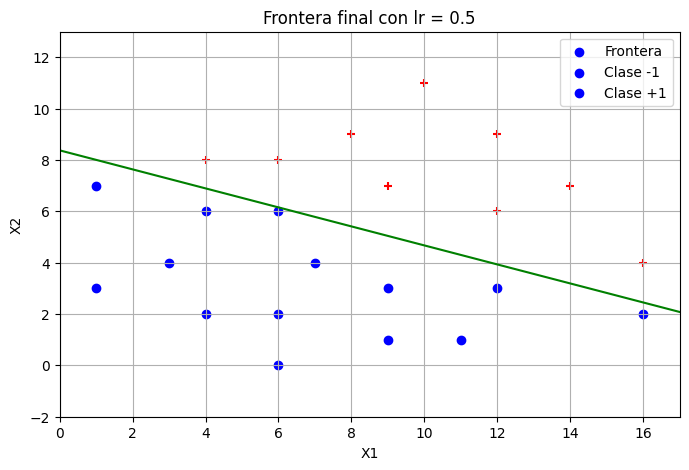

In [61]:
perceptron_plot(
    X,
    y,
    final_w,
    "Frontera final con lr = 0.5"
)

# ¿La frontera final separa correctamente las dos clases? ¿Qué diferencias observas respecto a la frontera inicial?

Si el entrenamiento alcanzó un error de cero, la frontera final separa correctamente los puntos del dataset. A diferencia de la frontera inicial, que fue generada con pesos aleatorios, la frontera final tiene una posición e inclinación ajustadas mediante el aprendizaje.

# Fase 6. Predicción con Nuevas Instancias
Utilizaremos el perceptrón entrenado para clasificar tres puntos que no pertenecen al dataset original.


Literal 6.a – Clasificación de nuevas instancias
Las instancias solicitadas son [5, 5], [10, 6] y [6, 10].

In [62]:
X_test = [
    [5, 5],
    [10, 6],
    [6, 10]
]

predicciones = []

print("Instancia | Salida predicha")
print("---------------------------")

for instancia in X_test:
    salida = perceptron_compute(instancia, final_w)
    predicciones.append(salida)

    print(instancia, " | ", salida)

Instancia | Salida predicha
---------------------------
[5, 5]  |  -1
[10, 6]  |  1
[6, 10]  |  1


El programa evalúa cada nuevo punto con los pesos finales del modelo y muestra la clase predicha. Los resultados concretos dependerán de la frontera aprendida.

#¿Las predicciones obtenidas son coherentes con la ubicación visual de los puntos respecto a la frontera de decisión?

Para comprobarlo, debemos ubicar los nuevos puntos en el plano. Las predicciones serán coherentes con el modelo si los puntos clasificados como +1 están del lado positivo de la frontera y los clasificados como -1 están del lado negativo.

# Literal 6.b – Dataset extendido
Agregaremos las tres instancias y sus predicciones a copias del dataset original.

Total original: 23
Total extendido: 26


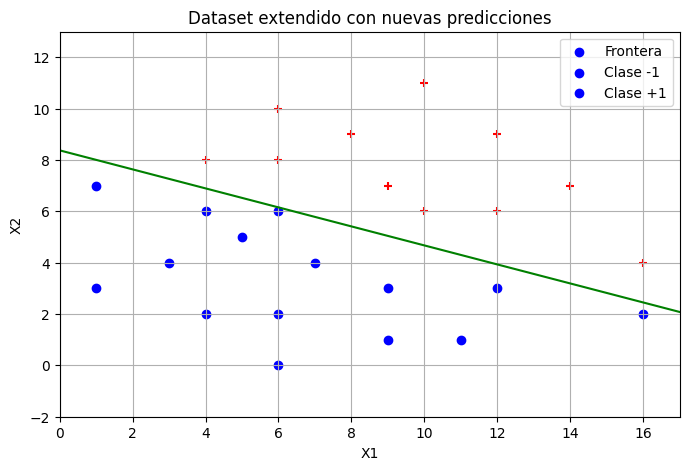

In [63]:
# Copiar dataset original
X_extendido = [fila.copy() for fila in X]
y_extendido = y.copy()

# Agregar nuevos puntos
for i in range(len(X_test)):
    X_extendido.append(X_test[i].copy())
    y_extendido.append(predicciones[i])

print("Total original:", len(X))
print("Total extendido:", len(X_extendido))

# Graficar dataset extendido
perceptron_plot(
    X_extendido,
    y_extendido,
    final_w,
    "Dataset extendido con nuevas predicciones"
)

# ¿Las nuevas instancias quedaron ubicadas en la región esperada del plano? ¿Alguna predicción parece discutible? Justifica tu respuesta.

Los nuevos puntos se ubican en las regiones que el perceptrón ha aprendido a clasificar. Las predicciones de los puntos cercanos a la frontera pueden considerarse más discutibles, porque pequeños cambios en sus coordenadas podrían cambiar su clasificación. Esto no demuestra que sean incorrectas, ya que no conocemos sus etiquetas reales.

# Fase 7. Evolución de la Frontera de Decisión
En esta fase vamos a observar cómo cambia la recta a medida que el perceptrón aprende.


#Literal 7.a – Seis estados del entrenamiento

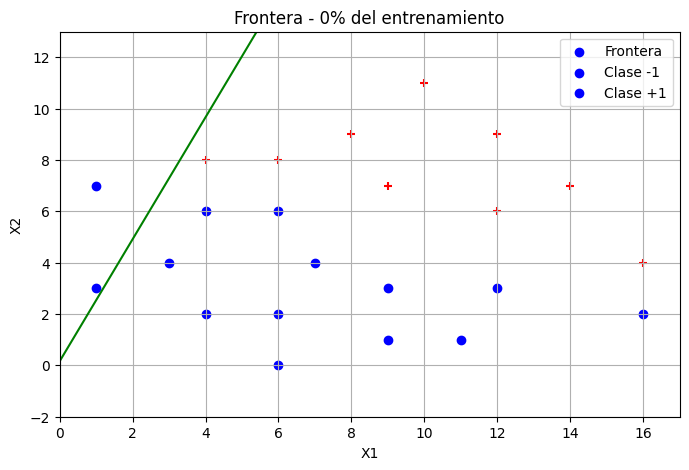

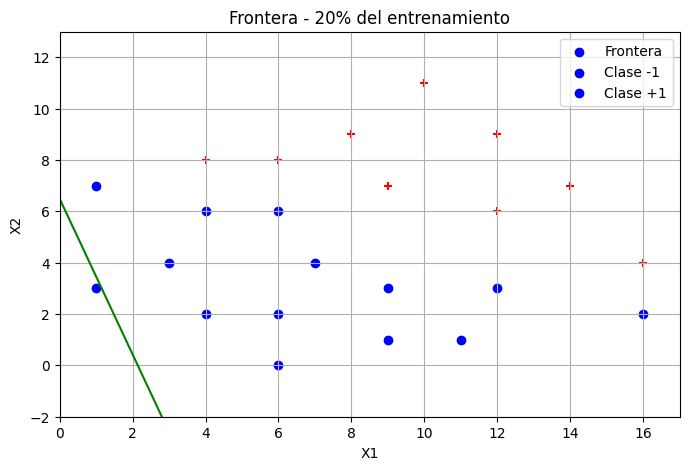

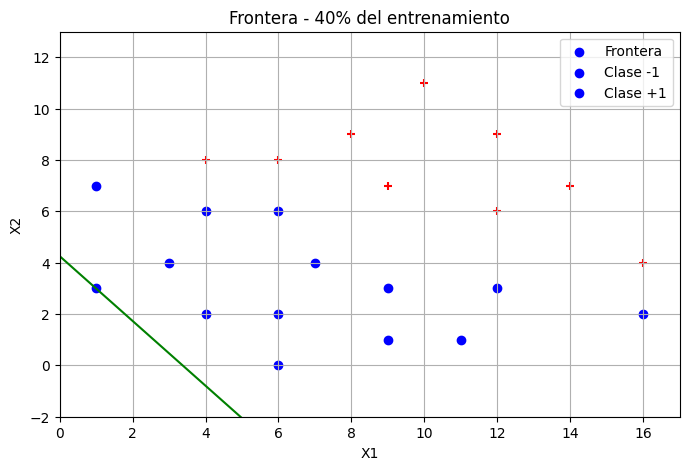

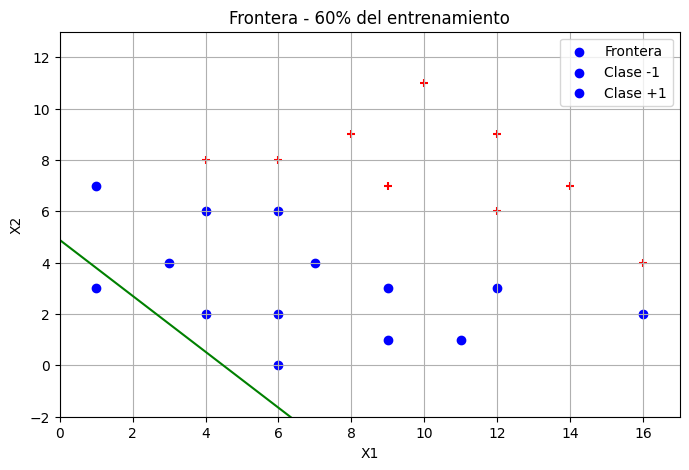

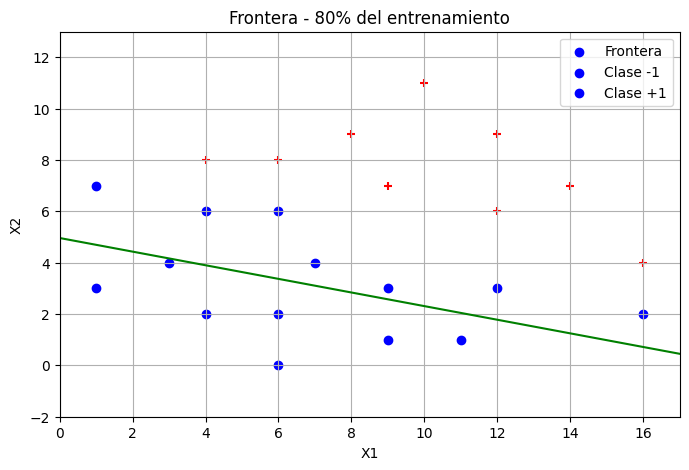

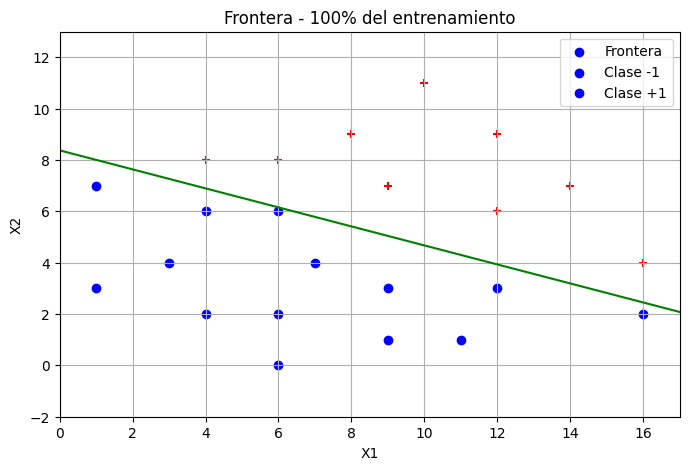

In [64]:
def graficar_evolucion(X, y, W_values):
    total = len(W_values) - 1

    if total < 5:
        indices = list(range(len(W_values)))
    else:
        indices = [
            0,
            round(total * 0.2),
            round(total * 0.4),
            round(total * 0.6),
            round(total * 0.8),
            total
        ]

    for indice in indices:
        porcentaje = indice / total * 100 if total > 0 else 0

        perceptron_plot(
            X,
            y,
            W_values[indice],
            f"Frontera - {porcentaje:.0f}% del entrenamiento"
        )

graficar_evolucion(X, y, W_values)

# ¿Qué ocurre con la frontera de decisión a medida que se actualizan los pesos? ¿El cambio parece estable o brusco?


La frontera cambia su inclinación y posición conforme se actualizan los pesos. Durante las primeras épocas pueden observarse cambios bruscos debido a las correcciones de clasificación. Posteriormente, si el perceptrón converge, la frontera deja de modificarse.

#Literal 7.b – Interpretación geométrica

#¿Qué peso parece influir más en la inclinación de la recta? ¿Qué papel cumple el bias en el desplazamiento de la frontera?

Los pesos w1 y w2 determinan conjuntamente la inclinación de la recta mediante su relación. El bias w0 permite desplazar la frontera de decisión sin modificar directamente su pendiente, siempre que los otros pesos permanezcan constantes.

# Fase 8. Evolución del Error
Literal 8.a – Gráfica de error


Crearemos una función llamada plot_error(E_values, title) que permita visualizar cómo cambia la tasa de error durante las épocas de entrenamiento.

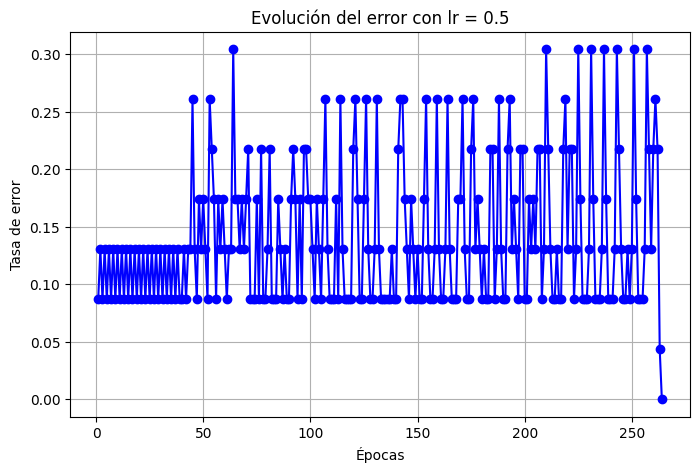

In [65]:
def plot_error(E_values, title):
    epocas = list(range(1, len(E_values) + 1))

    plt.figure(figsize=(8, 5))

    plt.plot(
        epocas,
        E_values,
        color="blue",
        marker="o"
    )

    plt.title(title)
    plt.xlabel("Épocas")
    plt.ylabel("Tasa de error")
    plt.grid(True)
    plt.show()

plot_error(
    E_values,
    "Evolución del error con lr = 0.5"
)

#¿El error disminuye de forma continua en todas las épocas? Si no ocurre así, ¿por qué puede aumentar o mantenerse igual durante algunos momentos del entrenamiento?


El error no necesariamente disminuye de manera continua. Puede aumentar o mantenerse igual porque cada actualización modifica la frontera de decisión y, aunque corrija una instancia, también puede provocar errores en otras. Lo importante es observar si finalmente consigue converger.

# Literal 8.b – Análisis de convergencia
Comprobaremos el error final del modelo.

In [66]:
error_final = E_values[-1]

print("Error final:", error_final)

if error_final == 0:
    print("El perceptrón logró converger")
else:
    print("El perceptrón no logró converger")

Error final: 0.0
El perceptrón logró converger


# Qué significa que el error final sea igual a cero? ¿Significa que el modelo es perfecto para cualquier dato futuro?

Un error final igual a cero significa que el perceptrón logró clasificar correctamente todas las instancias de entrenamiento durante la última época. Sin embargo, esto no garantiza que sea perfecto con datos futuros, porque podrían existir nuevas instancias con características diferentes a las utilizadas durante el entrenamiento.

# Fase 9. Comparación de Tasas de Aprendizaje

# Literal 9.a – Entrenamiento comparativo

In [67]:
tasas = [0.3, 0.5, 0.8]

# Un único vector inicial para comparar
pesos_iniciales = initialize_weights()

resultados = {}

for tasa in tasas:
    pesos_copia = pesos_iniciales.copy()

    wf, ep, act, Wv, Ev = perceptron_learning(
        X,
        y,
        pesos_copia,
        lr=tasa,
        max_epochs=1000
    )

    resultados[tasa] = {
        "pesos": wf,
        "epocas": ep,
        "actualizaciones": act,
        "W_values": Wv,
        "E_values": Ev,
        "error": Ev[-1]
    }

    print("Tasa de aprendizaje:", tasa)
    print("Pesos finales:", wf)
    print("Épocas:", ep)
    print("Actualizaciones:", act)
    print("Error final:", Ev[-1])
    print("----------------------------")

Tasa de aprendizaje: 0.3
Pesos finales: [-26.55865306434065, 1.3095617365902292, 2.7760056209275255]
Épocas: 69
Actualizaciones: 223
Error final: 0.0
----------------------------
Tasa de aprendizaje: 0.5
Pesos finales: [-52.55865306434063, 2.5095617365902285, 5.376005620927543]
Épocas: 94
Actualizaciones: 285
Error final: 0.0
----------------------------
Tasa de aprendizaje: 0.8
Pesos finales: [-89.15865306434058, 4.309561736590192, 9.976005620927472]
Épocas: 112
Actualizaciones: 316
Error final: 0.0
----------------------------


# ¿Por qué no sería justo comparar las tasas de aprendizaje usando pesos iniciales diferentes?

Porque los pesos iniciales influyen en el proceso de aprendizaje. Si utilizáramos pesos diferentes, no podríamos determinar si los cambios en el número de épocas o actualizaciones se deben a la tasa de aprendizaje o a la inicialización. Usar los mismos pesos permite una comparación más controlada.

#Literal 9.b – Gráficas comparativas

TASA DE APRENDIZAJE: 0.3


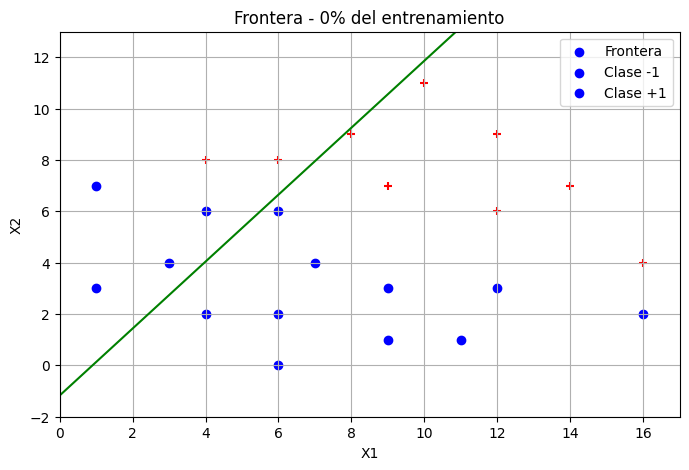

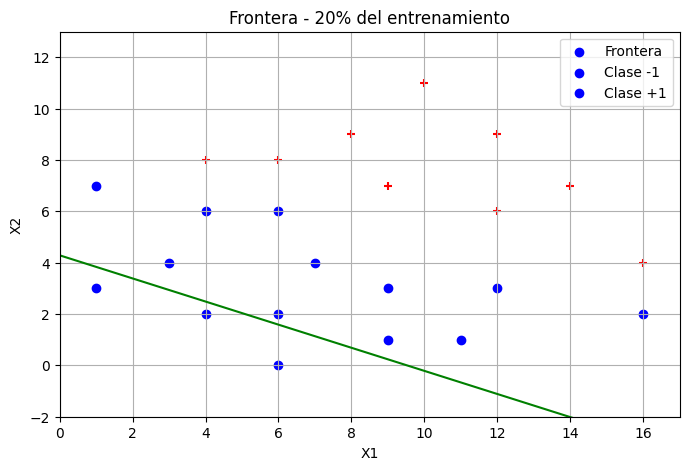

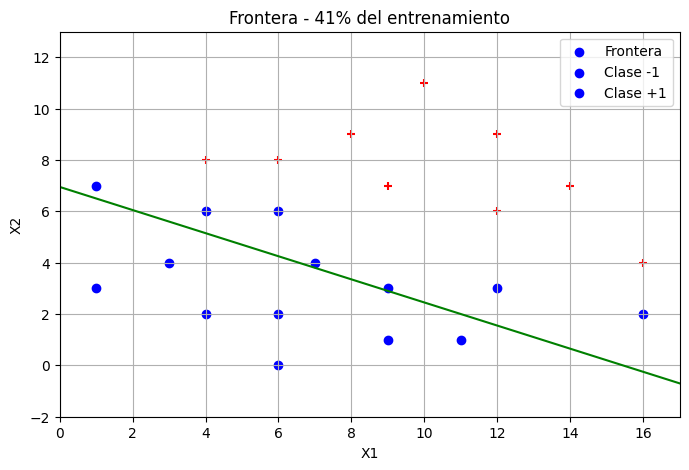

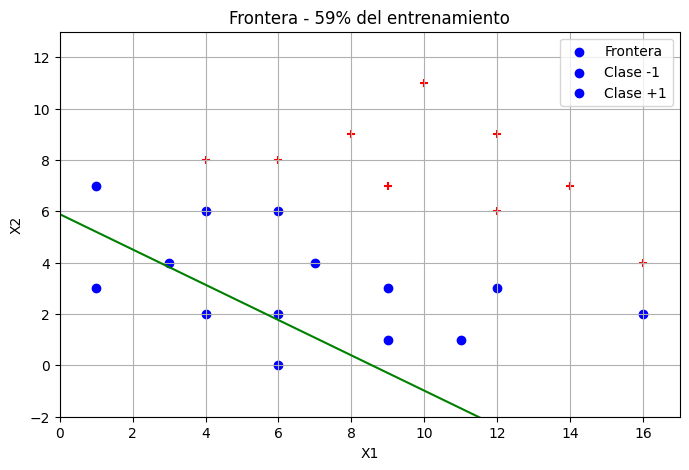

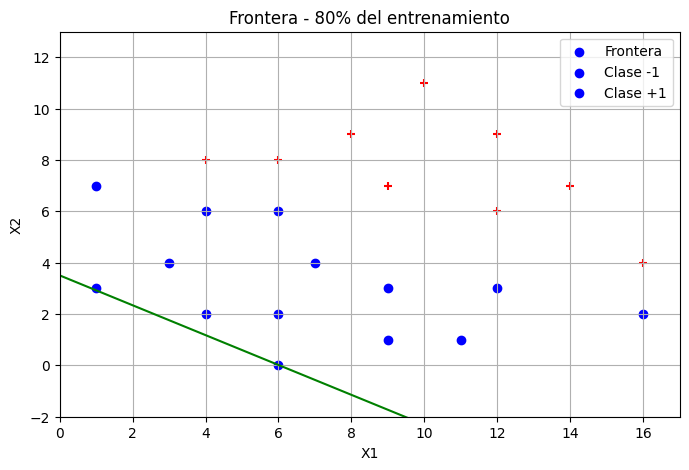

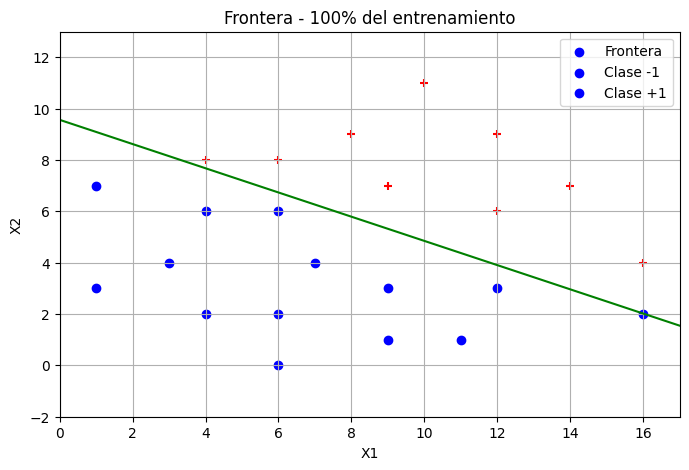

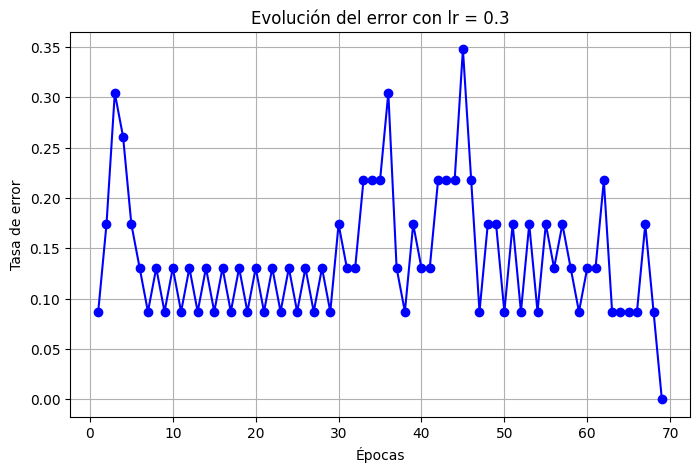

TASA DE APRENDIZAJE: 0.5


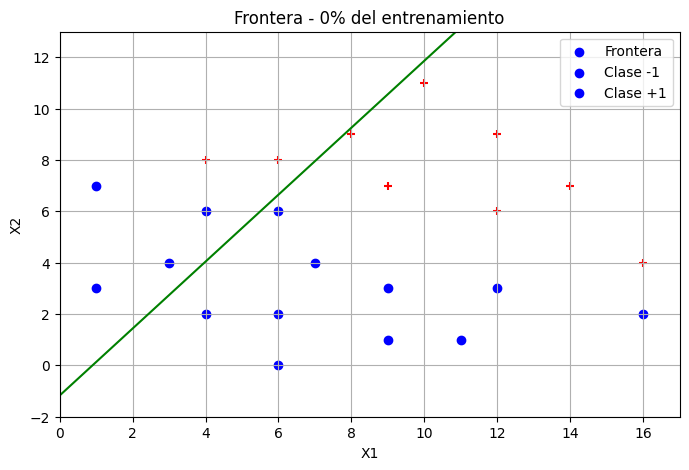

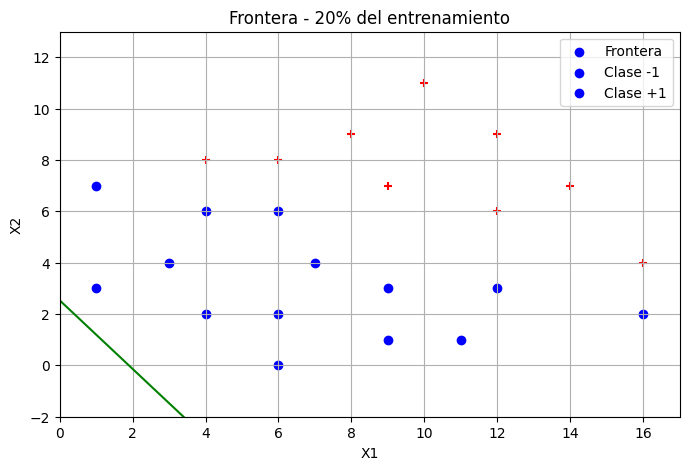

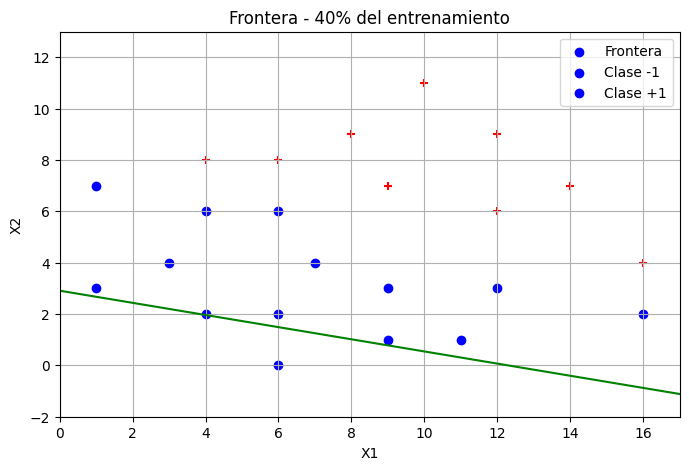

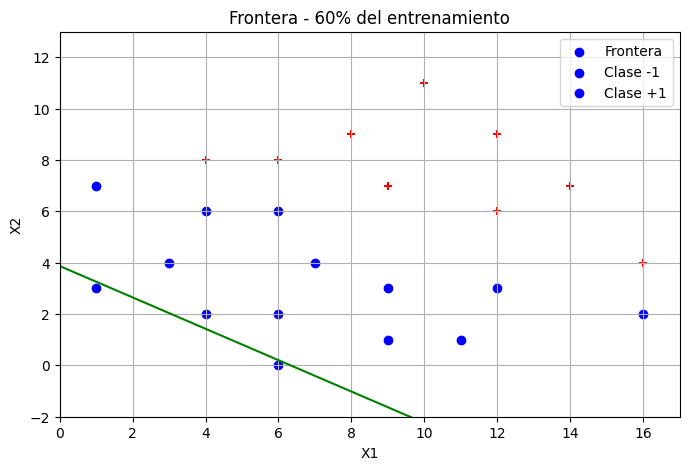

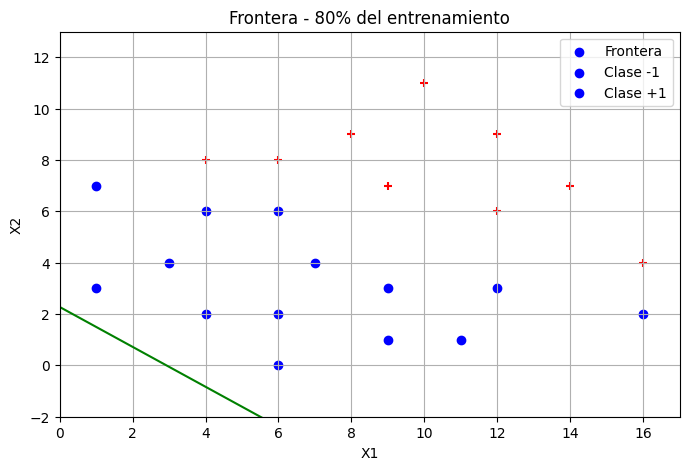

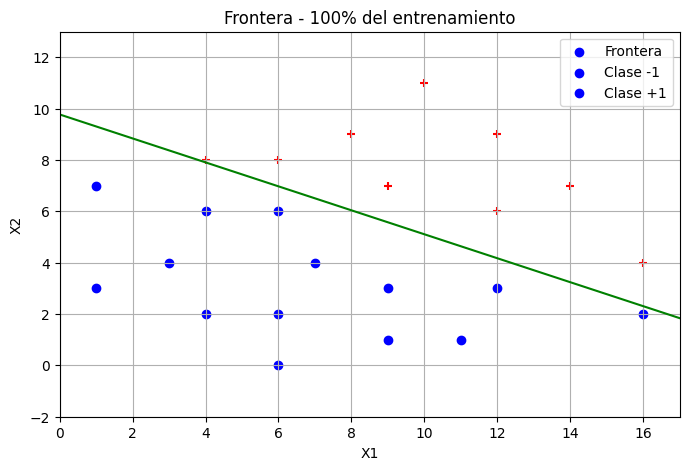

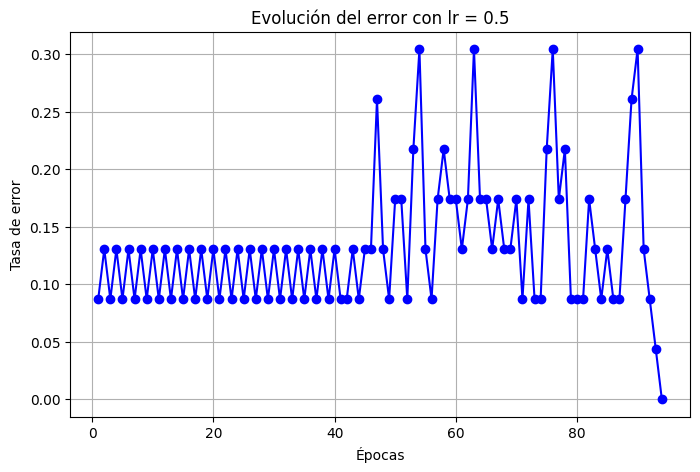

TASA DE APRENDIZAJE: 0.8


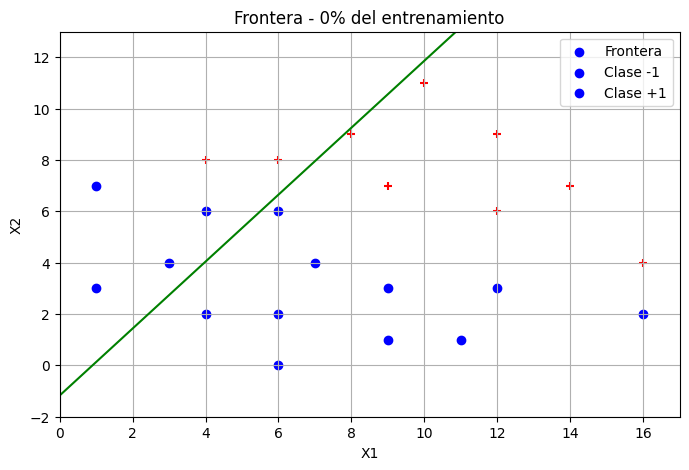

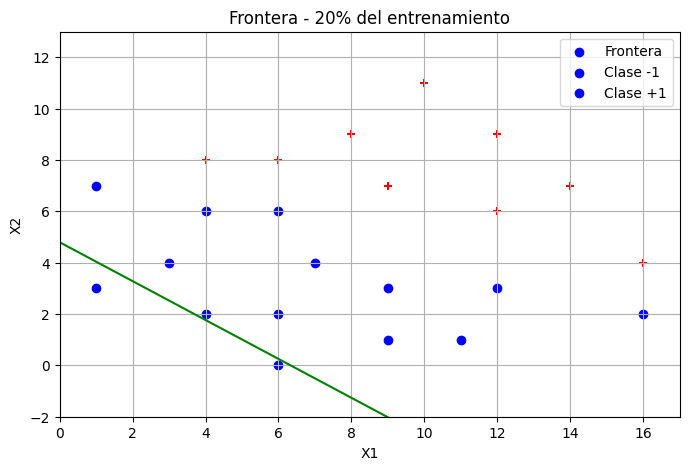

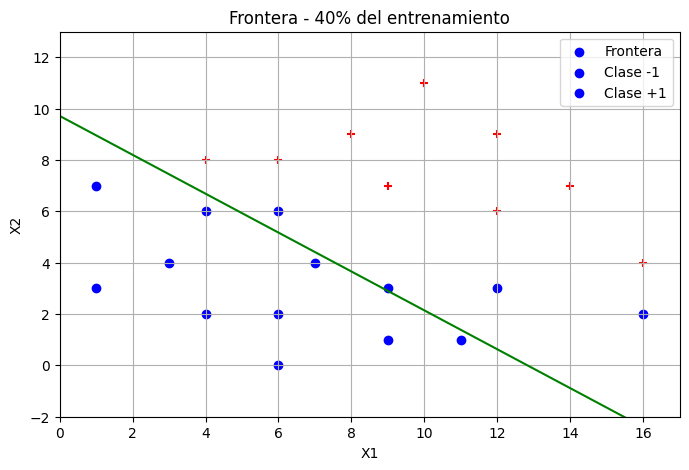

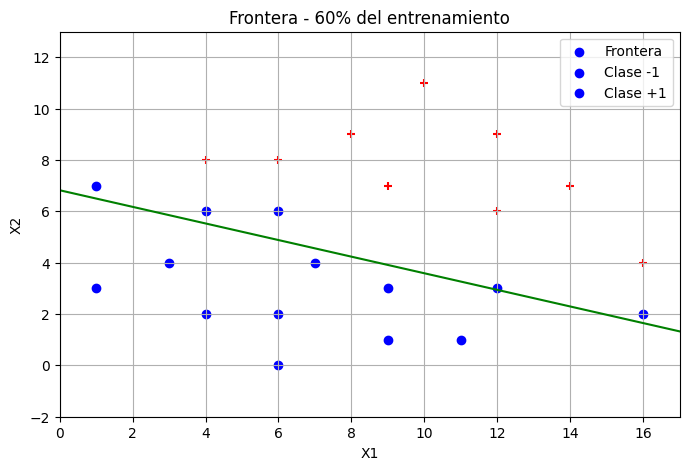

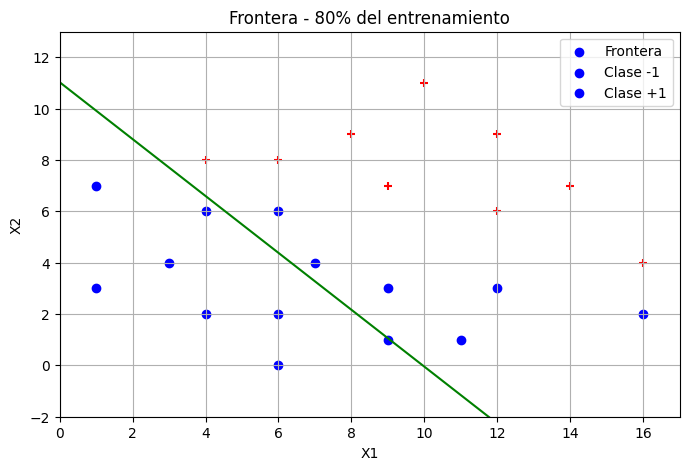

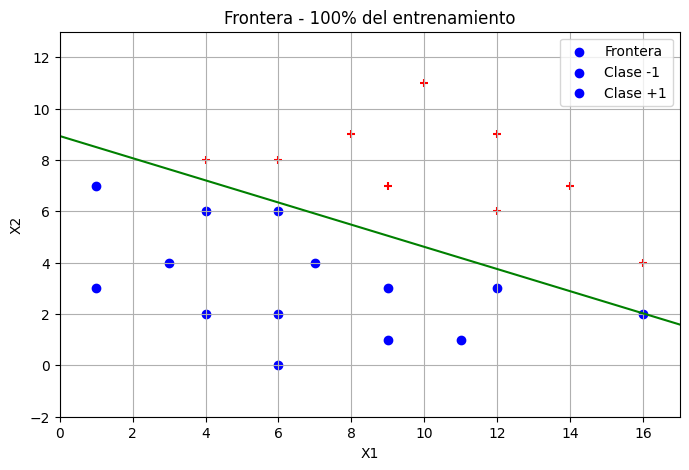

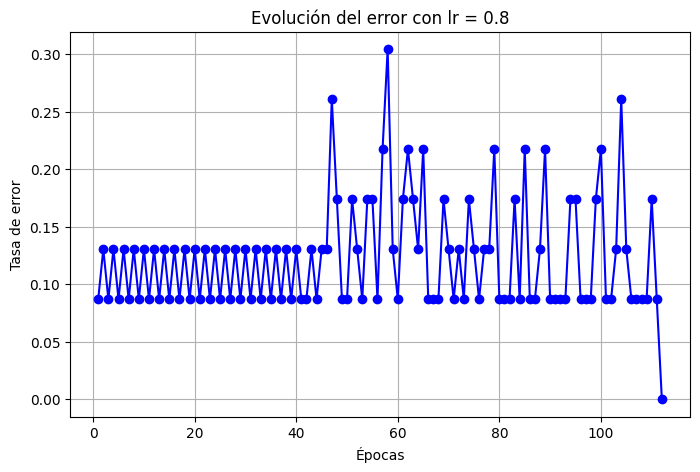

In [68]:
for tasa in tasas:
    print("================================")
    print("TASA DE APRENDIZAJE:", tasa)
    print("================================")

    datos = resultados[tasa]

    # Seis estados de la frontera
    graficar_evolucion(
        X,
        y,
        datos["W_values"]
    )

    # Evolución del error
    plot_error(
        datos["E_values"],
        f"Evolución del error con lr = {tasa}"
    )

# ¿Qué tasa de aprendizaje permitió alcanzar la convergencia con menos épocas? ¿Eso necesariamente significa que es la mejor tasa de aprendizaje?

La tasa que alcanzó la convergencia con menos épocas se puede identificar comparando los resultados obtenidos, considerando únicamente los entrenamientos con error final igual a cero. Sin embargo, no necesariamente es la mejor, porque también debemos considerar el número de actualizaciones, la estabilidad y el comportamiento del modelo.

#Literal 9.c – Tabla comparativa
Construiremos una tabla con las épocas, actualizaciones, error final y pesos finales.

In [69]:
print("TABLA COMPARATIVA")
print("-" * 90)

print(
    f"{'LR':<8}"
    f"{'Épocas':<12}"
    f"{'Actualizaciones':<20}"
    f"{'Error final':<15}"
    f"{'Pesos finales'}"
)

print("-" * 90)

for tasa in tasas:
    datos = resultados[tasa]

    print(
        f"{tasa:<8}"
        f"{datos['epocas']:<12}"
        f"{datos['actualizaciones']:<20}"
        f"{datos['error']:<15.4f}"
        f"{[round(p, 3) for p in datos['pesos']]}"
    )

TABLA COMPARATIVA
------------------------------------------------------------------------------------------
LR      Épocas      Actualizaciones     Error final    Pesos finales
------------------------------------------------------------------------------------------
0.3     69          223                 0.0000         [-26.559, 1.31, 2.776]
0.5     94          285                 0.0000         [-52.559, 2.51, 5.376]
0.8     112         316                 0.0000         [-89.159, 4.31, 9.976]


# ¿Los pesos finales son iguales para todas las tasas de aprendizaje? Si son diferentes, ¿por qué pueden producir igualmente una clasificación correcta?

Los pesos finales no necesariamente son iguales porque cada tasa de aprendizaje modifica la magnitud de las actualizaciones. Aun así, diferentes combinaciones de pesos pueden producir fronteras que separen correctamente las dos clases, porque no existe necesariamente una única recta válida para clasificar este dataset.

# ## Resultados obtenidos

1. Se implementó manualmente un perceptrón utilizando Python, incluyendo la inicialización de pesos, la función de activación bipolar, el cálculo de predicciones y la actualización de pesos durante el entrenamiento.

2. Se representaron gráficamente los puntos del dataset y las fronteras de decisión inicial y final, permitiendo observar cómo los pesos influyen en la clasificación.

3. Se registraron los errores y los pesos durante las épocas de entrenamiento para analizar la evolución del modelo.

4. Se realizaron predicciones sobre tres instancias nuevas y se incorporaron sus resultados a una copia del dataset original.

5. Se compararon tres tasas de aprendizaje: 0.3, 0.5 y 0.8, analizando las épocas, actualizaciones, errores finales y pesos obtenidos.

## Conclusiones

1. El perceptrón permite resolver problemas de clasificación binaria mediante una frontera de decisión lineal. Durante la práctica se comprendió cómo la actualización de pesos permite corregir errores de clasificación.

2. La tasa de aprendizaje influye en la magnitud de las actualizaciones y puede modificar la cantidad de épocas necesarias para alcanzar la convergencia.

3. La representación gráfica de las fronteras y de la evolución del error facilita la comprensión del proceso de aprendizaje, ya que permite observar los cambios del modelo durante el entrenamiento.

